# W10A · 실습 B · MLP·추가 정보·누적 앱

**딥러닝응용I(추천시스템) · 동덕여자대학교 데이터사이언스전공 · 유원상 교수 · 2026-2 · 2026-11-03**

이 노트북만 첫 셀부터 실행해 데이터 준비·학습·평가·앱까지 완료합니다. MF와 MLP/직업 모형의 같은 관측 분할을 비교하고, 장말 나이 경로를 설계합니다.

CPU 런타임에서 Drive에 사본을 저장하고 첫 셀부터 실행하세요. 설치 후 재시작 안내가 나오면 런타임을 재시작하고 처음부터 실행합니다. 개인 파일 업로드·API키·유료GPU가 필요하지 않습니다. `None`은 자신의 답을 적는 빈칸이며 기본 수업 변수와 분리되어 이후 실행을 막지 않습니다. 먼저 예상하고 실행 후 이유를 쓰세요.

아래 설치는 검토한 수업 ref를 사용합니다. 실제 Colab·공개 ref 검증은 배포 증거와 별도로 확인합니다.


In [ ]:
import os,sys,subprocess
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['TF_ENABLE_ONEDNN_OPTS']='0'
os.environ['GRADIO_ANALYTICS_ENABLED']='False'
IN_COLAB = 'google.colab' in sys.modules
COURSE_VERSION = '2026-fall-w10a'
if IN_COLAB:
    subprocess.run([sys.executable,'-m','pip','install','-q',
        f'luna-recommender-course[apps,neural] @ git+https://github.com/lunalab-ai/recommender.git@{COURSE_VERSION}',
        'gradio==6.26.0'],check=True)
    for name,wanted in [('tensorflow','2.21.0'),('keras','3.15.1')]:
        if name in sys.modules and getattr(sys.modules[name],'__version__',None)!=wanted:
            raise RuntimeError('설치가 갱신되었습니다. 런타임을 재시작하고 첫 셀부터 다시 실행하세요.')
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from IPython.display import display,Markdown
from luna_recsys.datasets import prepare_movielens
from luna_recsys.neural_recommenders import (fixed_forward,prepare_neural_data,
    build_mf,build_mlp,rating_metrics,predict_ratings,fit_neural)
from luna_recsys.model_comparison import definition_link
print('Python',sys.version.split()[0],'NumPy',np.__version__,'TensorFlow',tf.__version__,'Keras',keras.__version__)
print('수업 ref',COURSE_VERSION,'CPU로 실행 가능')


## 재사용 API를 먼저 읽기

`prepare_movielens(mode='synthetic')`는 독자 합성80명·18편·960평점을 메모리에 준비합니다. `mode='real'`은 공식 MovieLens를 다운로드/캐시하며 실패를 합성으로 숨기지 않습니다. `prepare_neural_data`는 키 결합·관측70/15/15분할 후 훈련에서만 ID 사전·평균·나이 스케일을 만듭니다.

`fixed_forward`는 주어진 합성 모수의 중간값 사전입니다. `build_mf/build_mlp`는 학습 전 Keras 모형을 만듭니다. 표 행 수에는 예약0이 포함됩니다. 모형 생성/학습은 Python·NumPy·TF의 전역 seed를 설정합니다. `fit_neural`은 실제 학습과 검증epoch선택 후 시험 평가를 수행합니다. `predict_ratings`는 평균을 복원한1차원 예측과 warm-ID mask를 반환합니다. `rating_metrics`는 두1차원 배열의 MSE/RMSE를 검사합니다. 다운로드 외에는 원자료를 파일로 복제하지 않습니다.

각 함수의 자세한 입력·반환·기본값은 강의의 API 안내와 아래 실제 정의 위치에서 확인하세요.


In [ ]:
functions=[prepare_movielens,prepare_neural_data,fixed_forward,build_mf,build_mlp,
           predict_ratings,rating_metrics,fit_neural]
display(Markdown('\n'.join(f'- [{f.__name__}]({definition_link(f,COURSE_VERSION)})' for f in functions)))


## 작은 MLP 중간값

`fixed_forward`는 실제 학습을 하지 않습니다. 기본 연결 입력은 길이6, 첫 Dense 값은[-1,2], ReLU 후[0,2], 중심화 출력은0.6입니다. 평균1을 더한1.6은 설명용 고정 점수입니다.

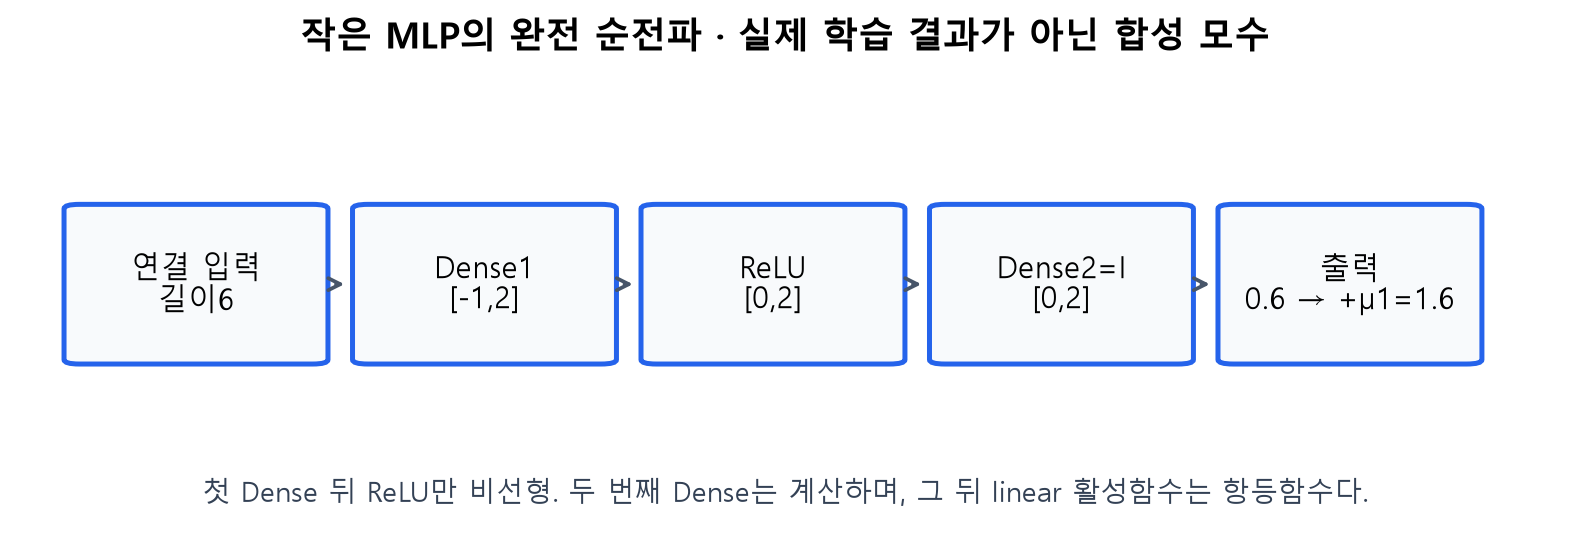


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w10a/course/notion/assets/w10a/08-mlp-forward.png)


In [ ]:
trace=fixed_forward()
display(pd.DataFrame({'before activation':trace['pre'],'after activation':trace['hidden']}))
print('연결',trace['z'],'평점',trace['mlp_rating'])


## L05 · Dense 손계산

워크북 L05의 가중합/ReLU/linear를 계산하세요. 힌트: W의 열마다 하나의 출력입니다. 자가점검: linear가 Dense 계산까지 생략하나요?


In [ ]:
my_dense=None
my_relu=None
print(my_dense,my_relu)


## 독립 데이터 준비와 같은 분할의 비교

모든 평균·사전·나이 스케일은 훈련 행에서 적합합니다. 같은 데이터/시드/K/학습 예산을 쓰고, 검증으로 선택하며 시험 결과로 다시 선택하지 않습니다. 각 모형의 추가 모수 수도 표시합니다. Keras MF와 MLP의 실제 학습은 아래에서 수행합니다.


In [ ]:
DATA_MODE='synthetic'
prepared=prepare_movielens(cache_dir='data/local/w10a',mode=DATA_MODE)
data=prepare_neural_data(prepared,max_rows=5000 if DATA_MODE=='real' else None)
print(prepared.description,'표 행 수',data.dimensions)
results={name:fit_neural(data,name,epochs=8) for name in ['mf','mlp','occupation']}
comparison=pd.DataFrame([{'model':name,'validation_rmse':r['metrics']['validation']['rmse'],
    'test_rmse':r['metrics']['test']['rmse'],'epoch':r['best_epoch'],
    'parameters':r['setting']['parameters']} for name,r in results.items()])
display(comparison)
chosen=comparison.sort_values('validation_rmse',kind='stable').iloc[0]['model']
print('검증으로 선택:',chosen,'시험으로 다시 선택하지 않습니다.')
print('평균 기준모형',results['mf']['baseline'])


## L06 · 키로 직업을 결합하기

워크북 L06의 평점 행[2,1]과 사용자 표를 올바르게 결합하세요. 힌트: user_id 키. 자가점검: 사용자 표 순서가 바뀌어도 같은가요?


In [ ]:
my_occupations=None
print(my_occupations)


## L08 · 검증 곡선으로 선택

워크북 L08의 네 에포크에서 선택할 번호와 이유를 적으세요. 힌트: 검증 최솟값. 자가점검: 시험 결과를 선택에 섞었나요?


In [ ]:
my_epoch=None
my_reason=None
print(my_epoch,my_reason)


## 연습문제6-1 · 나이 경로

나이는 연속형 값입니다. 훈련 평균·표준편차로 표준화해 Dense3+ReLU 경로로 보냅니다. 이 폭/활성함수는 수업용 선택입니다. 아래는 구조를 만드는 셀이고, 추가 학습은 선택사항입니다.


In [ ]:
age_model=build_mlp(*data.dimensions[:2],k=8,hidden=(16,8),n_occupations=data.dimensions[2],age=True)
print('입력',[value.name for value in age_model.inputs])
print('연결 폭',age_model.get_layer('joined_features').output.shape,'모수',age_model.count_params())
RUN_AGE_EXTENSION=False
if RUN_AGE_EXTENSION:
    age_result=fit_neural(data,'age',epochs=8)
    print(age_result['metrics'])


## L09 · 나이 표준화와 Dense

워크북 L09의 나이50을 훈련[20,40]으로 표준화한 후 Dense와 ReLU를 계산하세요. 힌트: 모집단 표준편차. 자가점검: 시험값으로 스케일을 새로 만들었나요?


In [ ]:
my_age_scaled=None
my_age_relu=None
print(my_age_scaled,my_age_relu)


## 누적 웹 앱을 조립하고 수정하기

`build_neural_explainer()`는 기존 FM 앱과 새 MF/MLP 계산 탭을 조립해 Blocks를 반환합니다. 여기서 학습하지 않으며, 위의 학습/성능 표와 구별합니다. `forward_view`는 문구·입력표·층별표·그림을 반환하고 `export_forward`는 합성 중간값 CSV를 임시폴더에 기록합니다. Gradio도 그림 캐시를 쓸 수 있습니다. 공유 주소는 실행 런타임에 의존합니다.


In [ ]:
from luna_recsys.neural_explainer import build_neural_explainer,forward_view,export_forward
summary,inputs,stages,plot=forward_view()
print(summary)
display(inputs,stages)
demo=build_neural_explainer()
if IN_COLAB:
    demo.launch(share=True,inline=False)
else:
    print('로컬 검증: 앱 객체와 callback을 구성했습니다. 실제 브라우저 조작은 별도 검증입니다.')


## L10 · 자신의 출력 함수를 화면에 연결

중심화 점수와 평균을 모두 표시하는 함수를 만들고 두 사용자 입력에서 문구와 값이 바뀌는지 확인하세요. 아래 None 기본값은 미완성 연습을 이후 흐름과 분리합니다. 힌트: fixed_forward 반환 키. 자가점검: 위젯→click 인자→함수→출력이 연결됐나요?


In [ ]:
def my_summary(user,item):
    # 자신의 문구로 수정하고 마지막 셀의 연결을 실행하세요.
    return None

RUN_MY_APP=False
if RUN_MY_APP:
    import gradio as gr
    my_demo=gr.Interface(my_summary,[gr.Dropdown(['A','B'],value='A'),
        gr.Dropdown(['P','Q'],value='P')],gr.Textbox(label='내 해석'),analytics_enabled=False)
    my_demo.launch(share=IN_COLAB,inline=False)


## 점검 퀴즈

1. 내적 대신 연결을 하면 출력 폭은 어떻게 되나요?
2. linear 활성함수와 Dense의 가중합은 무엇이 다른가요?
3. 직업 임베딩3개 값을 추가하면 입력 폭은 어떻게 변하나요?
4. 나이는 왜 직업ID와 다른 경로로 처리하나요?
5. 앱 입력 변경과 fit 학습을 구별해 설명하세요.

핵심 정리: 계산 경로를 읽고 중간값을 검산한 뒤, 분리된 자료에서 성능을 해석합니다.

참고: 주교재6.3–6.4/연습6-1, [Keras Dense](https://keras.io/api/layers/core_layers/dense/), [MovieLens README](https://files.grouplens.org/datasets/movielens/ml-100k-README.txt).


In [ ]:
np.testing.assert_allclose(trace['pre'],[-1,2],atol=1e-6)
assert np.isclose(trace['mlp_rating'],1.6)
assert len(results)==3
for name,r in results.items():
    assert np.isfinite(r['history'].to_numpy()).all()
    assert r['predictions']['test'].shape==(len(data.frames['test']),)
    assert r['counts']['test']['all']==len(data.frames['test'])
assert results['occupation']['setting']['parameters']>results['mlp']['setting']['parameters']
assert '1.600000' in forward_view()[0]
assert forward_view(user='B',item='Q')[0]!=forward_view()[0]
print('W10A_MLP_RUNTIME_PASS',prepared.mode)
